
# Optimizing Travel Costs for Dental Tourism

## 1. Introduction

International patients from DACH (Germany, Austria and Switzerland) travel to Varna, Bulgaria for dental treatment. Their travel expenses may include flights (round-trip ticket), hotel accommodation, and airport transfers in Varna.

This project aims to develop a Python model that compares travel options and identifies the lowest-cost feasible combination.

## 2. Project Objectives

- Calculate total travel costs.
- Compare flight, hotel, and transfer options.
- Consider the required length of stay.
- Find the cheapest feasible travel plan.
- Analyze how price changes affect total costs.

## 3. Data and Assumptions

The project initially uses illustrative data created for educational purposes. The prices do not represent actual market quotations.

The analysis focuses on travel expenses and excludes the cost of dental treatment.


In [2]:

# Example travel prices in euros (EUR)

flights = {
    "Flight A": 180,
    "Flight B": 220,
    "Flight C": 200
}

hotel_prices_per_night = {
    "Hotel A": 60,
    "Hotel B": 80,
    "Hotel C": 50
}

transfer_prices = {
    "Transfer A": 40,
    "Transfer B": 60
}

# Required length of stay
nights = 3

print("Available flights:", flights)
print("Hotel prices per night:", hotel_prices_per_night)
print("Transfer prices:", transfer_prices)
print("Required nights:", nights)


Available flights: {'Flight A': 180, 'Flight B': 220, 'Flight C': 200}
Hotel prices per night: {'Hotel A': 60, 'Hotel B': 80, 'Hotel C': 50}
Transfer prices: {'Transfer A': 40, 'Transfer B': 60}
Required nights: 3


In [3]:

# Select one travel option

flight_price = flights["Flight A"]
hotel_price = hotel_prices_per_night["Hotel A"]
transfer_price = transfer_prices["Transfer A"]

# Calculate the total travel cost
total_cost = (
    flight_price
    + nights * hotel_price
    + transfer_price
)

print(f"Total travel cost: €{total_cost}")


Total travel cost: €400


In [4]:

def calculate_total_cost(flight_price, hotel_price, transfer_price, nights):
    total = flight_price + hotel_price * nights + transfer_price
    return total


# Test the function
example_cost = calculate_total_cost(180, 60, 40, 3)

print(f"Example total cost: €{example_cost}")


Example total cost: €400


In [5]:

# Compare all possible travel combinations

best_option = None
lowest_cost = float("inf")

for flight_name, flight_price in flights.items():
    for hotel_name, hotel_price in hotel_prices_per_night.items():
        for transfer_name, transfer_price in transfer_prices.items():

            total = calculate_total_cost(
                flight_price,
                hotel_price,
                transfer_price,
                nights
            )

            if total < lowest_cost:
                lowest_cost = total
                best_option = (
                    flight_name,
                    hotel_name,
                    transfer_name
                )

print("Cheapest option:")
print("Flight:", best_option[0])
print("Hotel:", best_option[1])
print("Transfer:", best_option[2])
print(f"Total cost: €{lowest_cost}")


Cheapest option:
Flight: Flight A
Hotel: Hotel C
Transfer: Transfer A
Total cost: €370



## 4. Mathematical Model

The total travel cost is calculated using the following formula:

$$
C_{\text{total}} = C_{\text{flight}} + n \cdot C_{\text{hotel}} + C_{\text{transfer}}
$$

Where:

- $C_{\text{flight}}$ is the price of the flight.
- $n$ is the number of hotel nights.
- $C_{\text{hotel}}$ is the price per hotel night.
- $C_{\text{transfer}}$ is the transfer cost.

The objective is to minimize the total travel cost by selecting one flight, one hotel, and one transfer option.

Mathematically, this can be written as:

$$
C_{\min} = \min_{i,j,k}
\left(
F_i + nH_j + T_k
\right)
$$

where $F_i$, $H_j$, and $T_k$ represent the prices of the available flight, hotel, and transfer options.


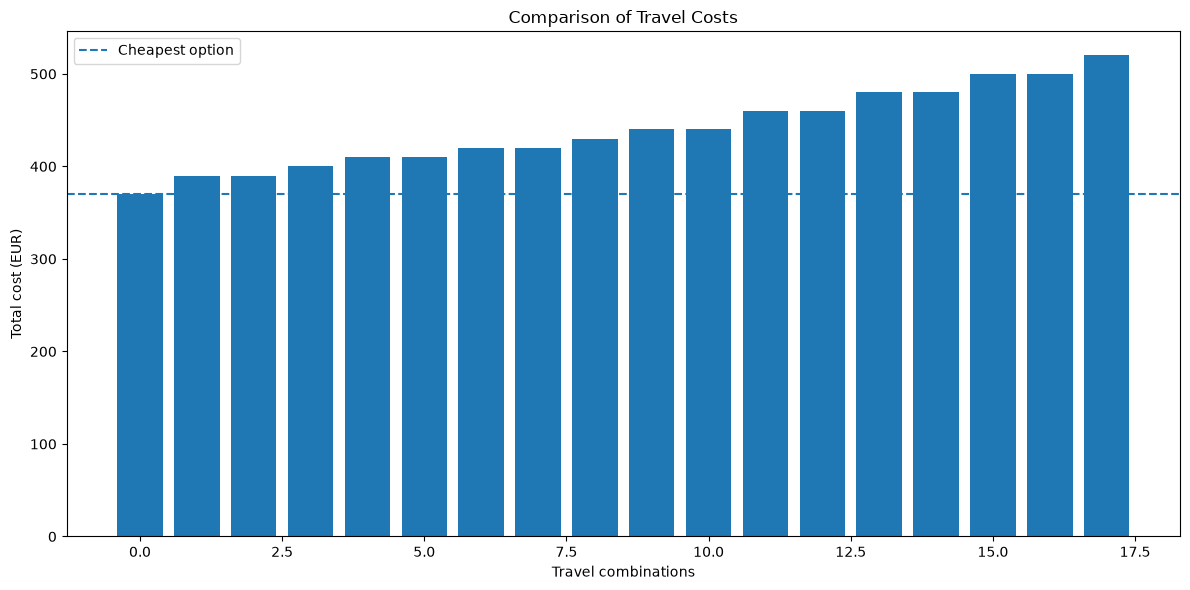

Number of combinations: 18
Cheapest cost: 370
Most expensive cost: 520


In [6]:

import matplotlib.pyplot as plt

# Store the total cost of each combination
all_costs = []

for flight_name, flight_price in flights.items():
    for hotel_name, hotel_price in hotel_prices_per_night.items():
        for transfer_name, transfer_price in transfer_prices.items():
            total = calculate_total_cost(
                flight_price,
                hotel_price,
                transfer_price,
                nights
            )

            label = f"{flight_name}, {hotel_name}, {transfer_name}"
            all_costs.append((label, total))

# Sort combinations from cheapest to most expensive
all_costs.sort(key=lambda item: item[1])

# Prepare data for the chart
labels = [item[0] for item in all_costs]
costs = [item[1] for item in all_costs]

plt.figure(figsize=(12, 6))
plt.bar(range(len(costs)), costs)
plt.axhline(lowest_cost, linestyle="--", label="Cheapest option")
plt.xlabel("Travel combinations")
plt.ylabel("Total cost (EUR)")
plt.title("Comparison of Travel Costs")
plt.legend()
plt.tight_layout()
plt.show()

print("Number of combinations:", len(all_costs))
print("Cheapest cost:", lowest_cost)
print("Most expensive cost:", max(costs))


In [7]:

# Calculate potential savings

most_expensive_cost = max(costs)
cheapest_cost = min(costs)

savings = most_expensive_cost - cheapest_cost
savings_percentage = (savings / most_expensive_cost) * 100

print(f"Cheapest option: €{cheapest_cost}")
print(f"Most expensive option: €{most_expensive_cost}")
print(f"Potential savings: €{savings}")
print(f"Potential savings percentage: {savings_percentage:.2f}%")


Cheapest option: €370
Most expensive option: €520
Potential savings: €150
Potential savings percentage: 28.85%


In [8]:
# Test the cost calculation function

assert calculate_total_cost(180, 60, 40, 3) == 400
assert calculate_total_cost(220, 50, 40, 3) == 410
assert calculate_total_cost(200, 80, 60, 3) == 500

print("All cost calculation tests passed!")

All cost calculation tests passed!


### Optimization Method: Exhaustive Search

The optimization problem is solved using exhaustive search. The algorithm evaluates every possible combination of flight, hotel, and transfer options and calculates its total travel cost.

Since there are 3 flight options, 3 hotel options, and 2 transfer options, the total number of combinations is:

$$N = 3 \times 3 \times 2 = 18$$

The algorithm compares the total costs of all 18 combinations and selects the combination with the minimum cost. Because every possible combination is evaluated, the algorithm finds the lowest-cost option among the combinations included in the model.

This method is suitable for the current problem because the number of options is small. However, the number of combinations grows multiplicatively as more options are added, which can make exhaustive search inefficient for larger problems.

The method also assumes that all listed combinations are feasible. In a real travel-planning scenario, availability, flight schedules, and other practical constraints would need to be considered.

## 5. Statistical Analysis of Travel Costs

To better understand the distribution of travel costs, we calculate the mean, median, and range of all 18 possible travel combinations.

These statistics help us compare the typical cost with the cheapest and most expensive options.

In [10]:
import statistics

mean_cost = statistics.mean(costs)
median_cost = statistics.median(costs)
cost_range = max(costs) - min(costs)

print(f"Mean travel cost: €{mean_cost:.2f}")
print(f"Median travel cost: €{median_cost:.2f}")
print(f"Minimum travel cost: €{min(costs)}")
print(f"Maximum travel cost: €{max(costs)}")
print(f"Range of travel costs: €{cost_range}")

Mean travel cost: €440.00
Median travel cost: €435.00
Minimum travel cost: €370
Maximum travel cost: €520
Range of travel costs: €150


### Interpretation of Statistical Results

The mean travel cost is €440, while the median is €435. These values indicate the central tendency of the 18 possible travel combinations.

The minimum cost is €370, and the maximum cost is €520, resulting in a range of €150. This shows that the choice of flight, hotel, and transfer can have a meaningful impact on total travel expenses.

The cheapest combination provides a lower-cost option under the assumptions of this model. However, the results are based on illustrative prices and do not account for availability, travel convenience, or changes in real market prices.

## 6. Hotel Price Sensitivity Analysis

This section examines how changes in hotel prices affect the total travel cost.

The analysis uses illustrative data for educational purposes.

In [11]:
# Analyze the effect of hotel price changes

flight_price = 180
hotel_price = 50
transfer_price = 40
nights = 3

price_increase = 10

original_cost = calculate_total_cost(
    flight_price, hotel_price, transfer_price, nights
)

new_cost = calculate_total_cost(
    flight_price, hotel_price + price_increase,
    transfer_price, nights
)

print(f"Original total cost: €{original_cost}")
print(f"New total cost: €{new_cost}")
print(f"Increase in total cost: €{new_cost - original_cost}")

Original total cost: €370
New total cost: €400
Increase in total cost: €30


### Interpretation of Results

When the hotel price increases by €10 per night, the total travel cost increases by €30 for a three-night stay.

This happens because the hotel cost depends on both the price per night and the number of nights. The flight and transfer prices remain unchanged in this analysis.

The results show that even a small change in the nightly hotel rate can affect the total travel budget. This sensitivity analysis can help travelers understand how changes in accommodation prices influence their overall expenses.

## 7. Experiment: Effect of Length of Stay

The length of stay affects the total travel cost because accommodation is charged per night. In this experiment, we compare the minimum travel cost for stays of 1, 3, 5, and 7 nights.

For each stay duration, the algorithm evaluates all flight, hotel, and transfer combinations and identifies the lowest-cost option. This allows us to examine how accommodation duration influences the minimum travel budget.

In [15]:

stay_durations = [1, 3, 5, 7]
stay_results = []

for stay_nights in stay_durations:
    best_cost = float("inf")
    best_combination = None

    for flight_name, flight_price in flights.items():
        for hotel_name, hotel_price in hotel_prices_per_night.items():
            for transfer_name, transfer_price in transfer_prices.items():

                total_cost = calculate_total_cost(
                    flight_price,
                    hotel_price,
                    transfer_price,
                    stay_nights
                )

                if total_cost < best_cost:
                    best_cost = total_cost
                    best_combination = (
                        flight_name,
                        hotel_name,
                        transfer_name
                    )

    stay_results.append({
        "nights": stay_nights,
        "minimum_cost": best_cost,
        "combination": best_combination
    })

for result in stay_results:
    print(
        f'{result["nights"]} nights: '
        f'€{result["minimum_cost"]} - '
        f'{result["combination"]}'
    )


1 nights: €270 - ('Flight A', 'Hotel C', 'Transfer A')
3 nights: €370 - ('Flight A', 'Hotel C', 'Transfer A')
5 nights: €470 - ('Flight A', 'Hotel C', 'Transfer A')
7 nights: €570 - ('Flight A', 'Hotel C', 'Transfer A')


### Interpretation of Results

The experiment shows that the minimum travel cost increases as the length of stay increases. With the current illustrative prices, each additional hotel night adds €50 to the total cost because Hotel C is the cheapest accommodation option at €50 per night.

The same flight, hotel, and transfer combination remains the cheapest for all four stay durations. This happens because the flight and transfer prices remain fixed, while the hotel cost increases proportionally with the number of nights.

These results apply only to the prices and options included in this model. In practice, longer stays may involve different hotel rates, discounts, or other travel constraints.

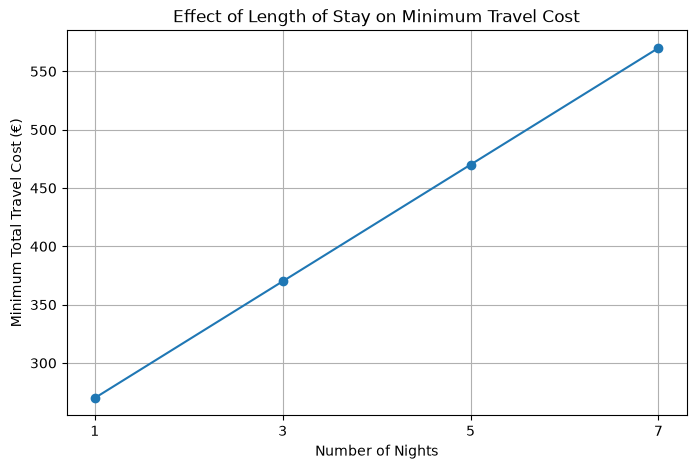

In [16]:

import matplotlib.pyplot as plt

nights = [result["nights"] for result in stay_results]
minimum_costs = [result["minimum_cost"] for result in stay_results]

plt.figure(figsize=(8, 5))
plt.plot(nights, minimum_costs, marker="o")
plt.title("Effect of Length of Stay on Minimum Travel Cost")
plt.xlabel("Number of Nights")
plt.ylabel("Minimum Total Travel Cost (€)")
plt.xticks(nights)
plt.grid(True)
plt.show()


## 8. Experiment: Seasonal Variation in Hotel Prices

Hotel prices may vary depending on the season. To investigate how seasonality affects the total travel budget, this experiment assumes that hotel prices are 20% higher during the summer months of June, July, and August.

The model uses the original hotel prices from September to May and applies a 20% increase from June to August. Flight and transfer prices remain unchanged, and the length of stay is fixed at three nights.

This is an illustrative assumption for the analysis and does not represent verified pricing data from specific hotels.

The objective is to compare the total travel costs in summer and outside the summer season.

In [17]:
def calculate_seasonal_hotel_price(base_price, month):
    if month in [6, 7, 8]:
        return base_price * 1.20
    else:
        return base_price

In [18]:
base_price = 50

print("May:", calculate_seasonal_hotel_price(base_price, 5))
print("June:", calculate_seasonal_hotel_price(base_price, 6))
print("August:", calculate_seasonal_hotel_price(base_price, 8))
print("September:", calculate_seasonal_hotel_price(base_price, 9))

May: 50
June: 60.0
August: 60.0
September: 50
